In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH

In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = (
    ('a', 'fitted_a'),
    ('e', 'fitted_e'),
    ('periapsis_phase', 'fitted_periapsis_phase'),
    ('Macc', 'fitted_Macc'),
    ('Porb', 'fitted_porb')
)

In [5]:
results = pandas.read_parquet(TIMESERIES_TABLE_PATH)
# results['err'] = numpy.mean(numpy.array([err(results[o], results[m]) for o, m in params]), axis=0)
len(results)

2500

In [6]:
for o, m in params:
    results[f'{o} - {m}'] = numpy.abs(results[o] - results[m])
    results[f'({o} - {m})/{o}'] = numpy.abs((results[o] - results[m])/results[o])

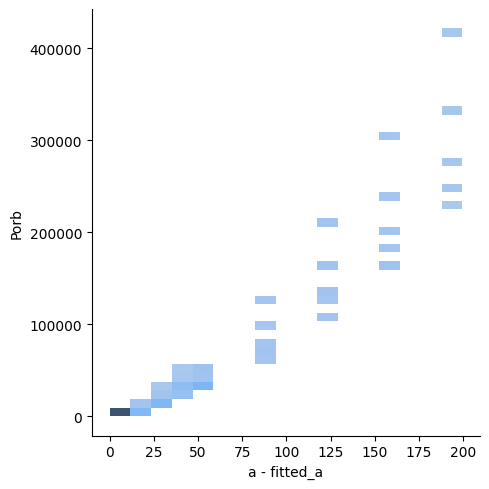

In [7]:
seaborn.displot(data=results, x='a - fitted_a', y='Porb')

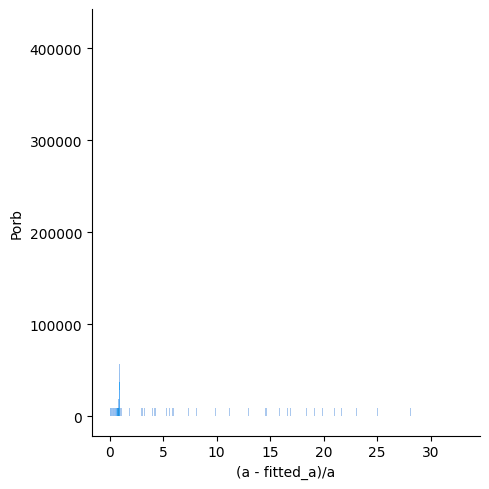

In [8]:
seaborn.displot(data=results, x='(a - fitted_a)/a', y='Porb')
# pyplot.xscale('log')

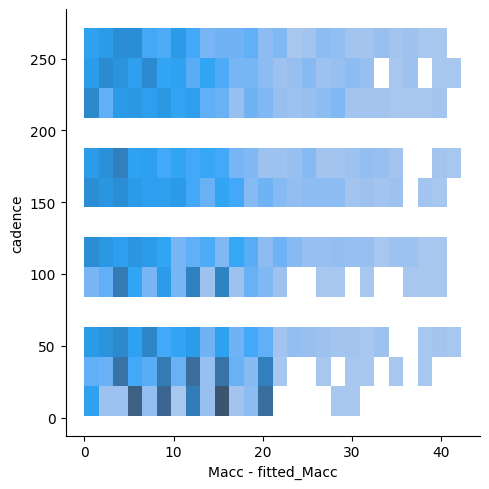

In [9]:
seaborn.displot(data=results, x='Macc - fitted_Macc', y='cadence')

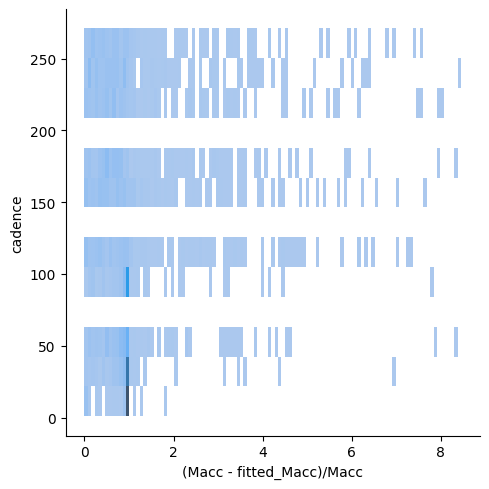

In [10]:
seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='cadence')
# pyplot.xscale('log')

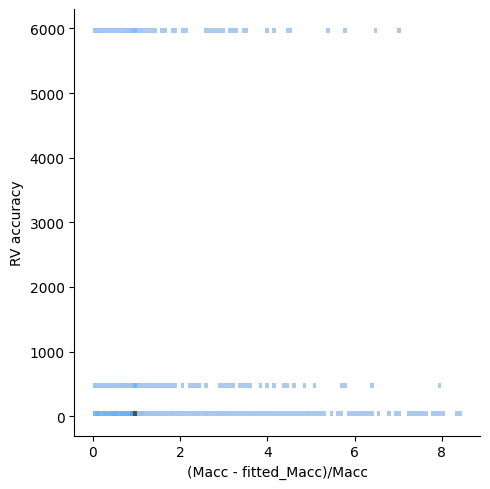

In [16]:
seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='RV accuracy')
# pyplot.yscale('log')

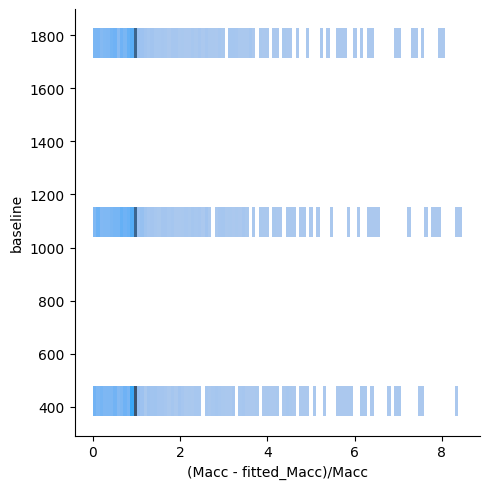

In [11]:
seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='baseline')
# pyplot.xscale('log')

<Axes: xlabel='(Macc - fitted_Macc)/Macc', ylabel='Macc'>

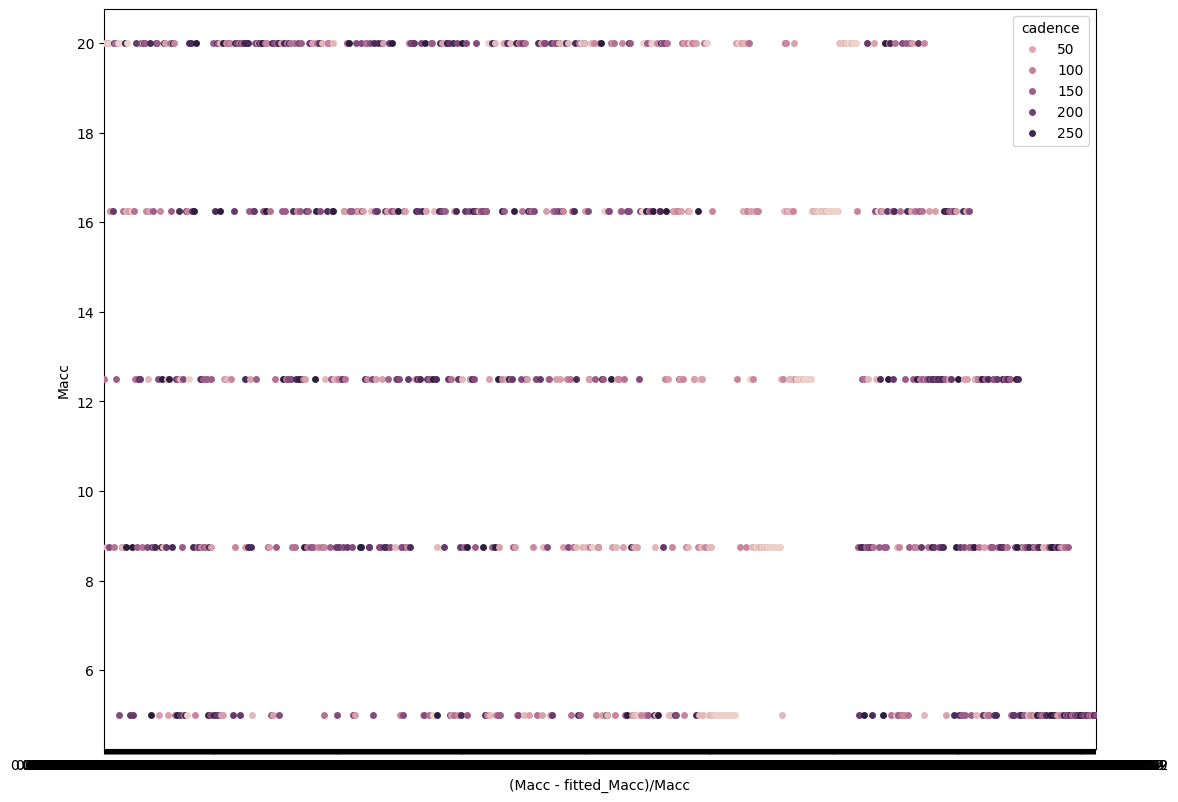

In [12]:
seaborn.swarmplot(data=results.sample(1000), hue='cadence', y='Macc', x='(Macc - fitted_Macc)/Macc', dodge=True)

In [13]:
seaborn.scatterplot(data=results, x='cadence', y='err', hue='RV accuracy')
# pyplot.xscale('log')

ValueError: Could not interpret value `err` for `y`. An entry with this name does not appear in `data`.

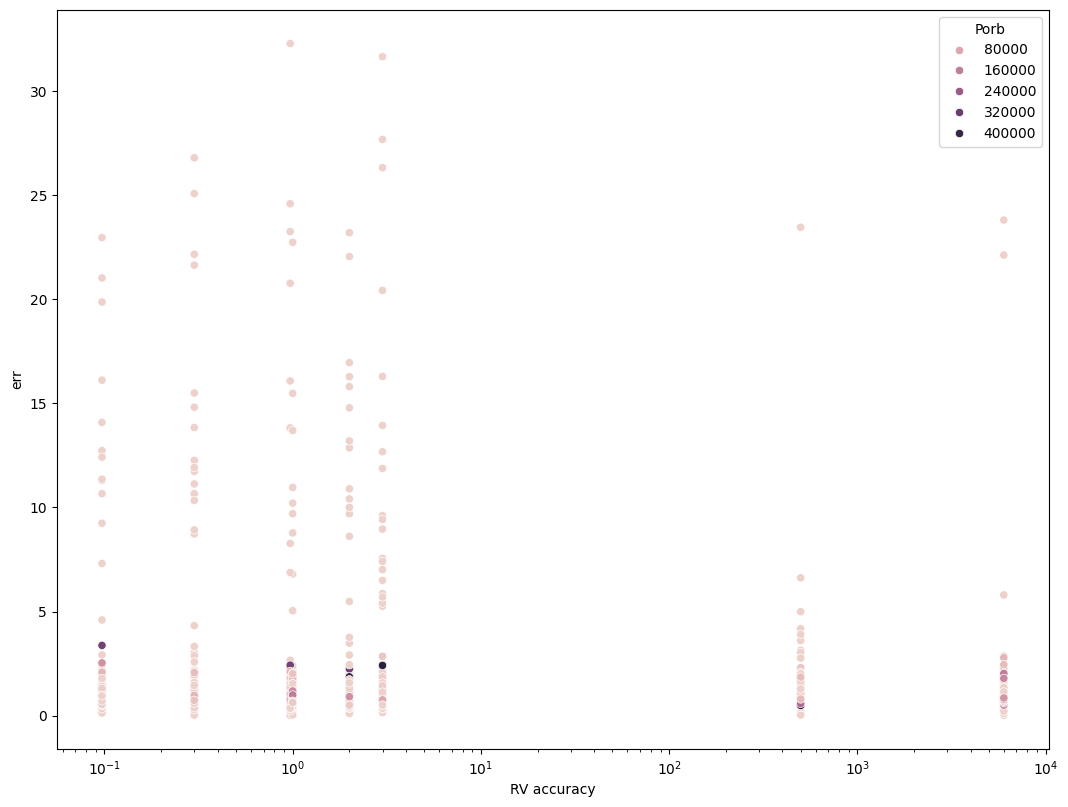

In [ ]:
seaborn.scatterplot(data=results, x='RV accuracy', y='err', hue='Porb')
pyplot.xscale('log')

<Axes: xlabel='baseline', ylabel='err'>

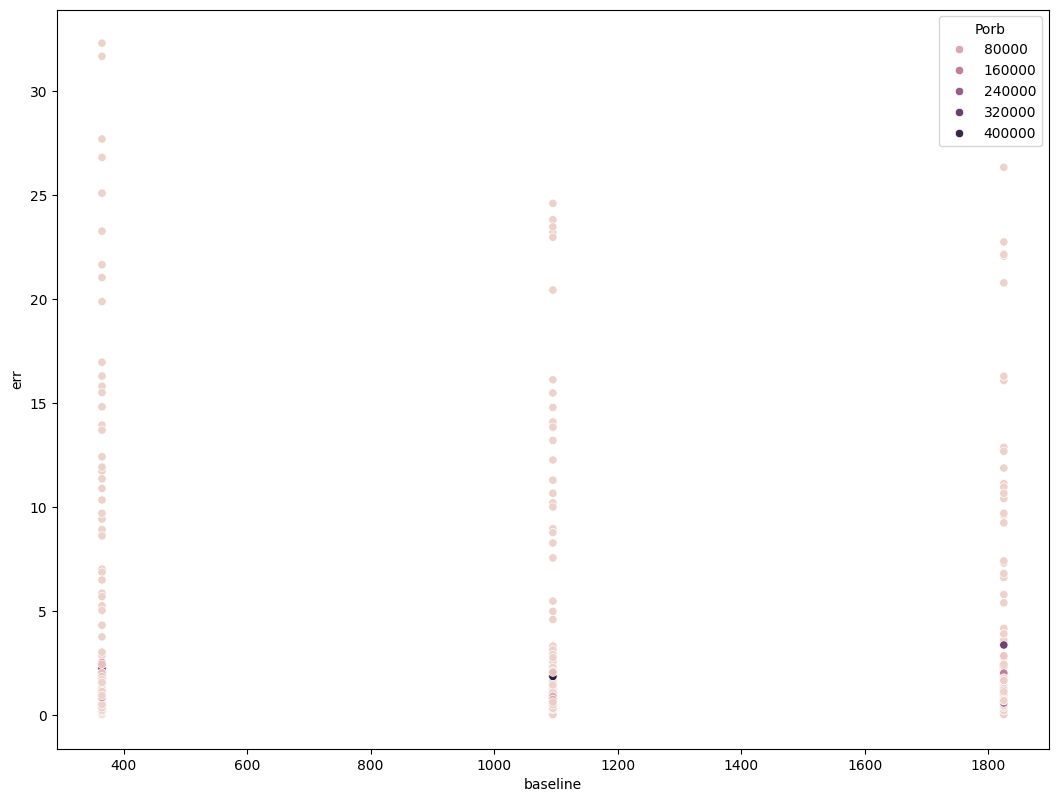

In [ ]:
seaborn.scatterplot(data=results, x='baseline', y='err', hue='Porb')